# Task 1(a): CNN trained from scratch

**Method.** We start from a simple baseline (a CNN with one convolution layer) and improve it **one change at a time**. For each change we write down what we expect (for example "augmentation will reduce overfitting"), train the model twice with two different random seeds, and compare the average **validation** accuracy. We keep the change only if it beats the best model so far. The test split is used only once, at the very end.

All our models use the same split (`data/split.csv`: 70 % train, 15 % validation, 15 % test, with the same share of each class in each part), so the CNN and the ViT can be compared on exactly the same images.

## 0. Colab setup (skipped automatically on a local machine)

Put two files in Google Drive in `MyDrive/ecse551/`: the Kaggle zip `fall-2026-ecse-551-task-1.zip` and `split.csv` (from `data/` in the repo). This cell connects Google Drive, unzips the data on the Colab machine (faster to read), and saves everything written to `outputs/` in `MyDrive/ecse551/outputs`, so the results are kept after the session ends.

In [1]:
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE, ROOT = "/content/drive/MyDrive/ecse551", "/content/ecse551"
    if not os.path.exists(f"{ROOT}/data/fall-2026-ecse-551-task-1"):
        os.makedirs(f"{ROOT}/data", exist_ok=True)
        os.system(f"unzip -q '{DRIVE}/fall-2026-ecse-551-task-1.zip' -d {ROOT}/data/fall-2026-ecse-551-task-1")
    if os.path.exists(f"{DRIVE}/split.csv"): os.system(f"cp '{DRIVE}/split.csv' {ROOT}/data/")
    os.makedirs(f"{DRIVE}/outputs", exist_ok=True); os.makedirs(f"{ROOT}/notebooks", exist_ok=True)
    if not os.path.exists(f"{ROOT}/outputs"): os.symlink(f"{DRIVE}/outputs", f"{ROOT}/outputs")
    os.chdir(f"{ROOT}/notebooks")
    print("Colab ready:", os.listdir(f"{ROOT}/data"))

Mounted at /content/drive
Colab ready: ['split.csv', 'fall-2026-ecse-551-task-1']


## 1. Data

In [2]:
import os, json, math, pandas as pd, seaborn as sns, numpy as np, matplotlib.pyplot as plt, torch, torch.nn as nn, torch.nn.functional as F
from PIL import Image                                   # to open image files
from sklearn.model_selection import train_test_split    # to create the train / val / test split
from sklearn.metrics import ConfusionMatrixDisplay

# Use the GPU if there is one: "cuda" = NVIDIA GPU (Colab), "mps" = Apple GPU (Mac), otherwise the CPU
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print(device)

cuda


In [3]:
PATH = "../data/fall-2026-ecse-551-task-1"

train = pd.read_csv(PATH+"/train.csv")   # 21,098 rows: image path + class name
test = pd.read_csv(PATH+"/test.csv")     # 5,286 rows: Kaggle image names, no labels

Y_train = train["label_name"]
X_train = train["image_path"]
X_test = test["id"]

# The csv paths start with "RIVAL10/..."; the files are in "archive/RIVAL10_Kaggle/..."
def clean_path(path) :
  clean_path = path[7:]                  # drop "RIVAL10"
  clean_path = "archive/RIVAL10_Kaggle" + clean_path
  return clean_path

def clean_path_test(path):
  path = "archive/RIVAL10_Kaggle/test/test_images/" + path
  return path

X_train = X_train.apply(clean_path)
X_test = X_test.apply(clean_path_test)

print(X_train)
print(X_test)
print(Y_train)

0        archive/RIVAL10_Kaggle/train/ordinary/n0446766...
1        archive/RIVAL10_Kaggle/train/ordinary/n0164437...
2        archive/RIVAL10_Kaggle/train/ordinary/n0212339...
3        archive/RIVAL10_Kaggle/train/ordinary/n0269037...
4        archive/RIVAL10_Kaggle/train/ordinary/n0153282...
                               ...                        
21093    archive/RIVAL10_Kaggle/train/ordinary/n0310024...
21094    archive/RIVAL10_Kaggle/train/ordinary/n0212407...
21095    archive/RIVAL10_Kaggle/train/ordinary/n0153282...
21096    archive/RIVAL10_Kaggle/train/ordinary/n0269037...
21097    archive/RIVAL10_Kaggle/train/ordinary/n0242302...
Name: image_path, Length: 21098, dtype: object
0       archive/RIVAL10_Kaggle/test/test_images/00000.png
1       archive/RIVAL10_Kaggle/test/test_images/00001.png
2       archive/RIVAL10_Kaggle/test/test_images/00002.png
3       archive/RIVAL10_Kaggle/test/test_images/00003.png
4       archive/RIVAL10_Kaggle/test/test_images/00004.png
              

# Checking stats about the data

,count
label_name,
frog,2127
bird,2126
car,2126
equine,2122
cat,2122
dog,2119
ship,2119
deer,2116
plane,2110


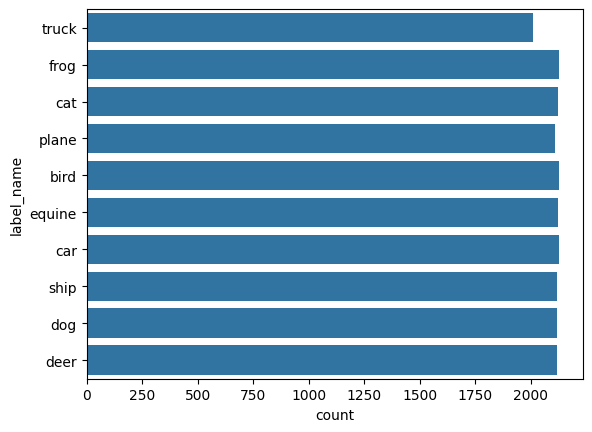

In [4]:
# Number of images per class: about 2,100 each, so the dataset is balanced
g = sns.countplot(Y_train)

Y_train.value_counts()

In [5]:
def read_image(path) :
  # file -> array of shape (224, 224, 3): height, width, colour (red, green, blue), values 0-255
  return np.array(Image.open(PATH+"/"+path).convert("RGB"))


In [6]:
(X_train == "").any()
#check no test has null

np.False_

In [7]:
# Check one image: its shape and its pixel range
print(read_image(X_train[0]).shape)
print(read_image(X_train[0]).max())
print(read_image(X_train[0]).min())

(224, 224, 3)
255
0


# Prepare Data for pytorch

In [8]:
#Prepare Data: load every image into memory (takes a few minutes)
X_train = X_train.apply(read_image)
X_test = X_test.apply(read_image)

In [9]:
# Class name -> number (the network predicts numbers 0-9). The same encoding is used in every notebook.
encodings={
    "truck":0,
    "frog":1,
    "cat":2,
    "plane":3,
    "bird":4,
    "car":5,
    "equine":6,
    "ship":7,
    "deer":8,
    "dog":9,
}

reverse_encodings = {v: k for k, v in encodings.items()}   # number -> class name

Y_train = Y_train.replace(encodings)

/tmp/ipykernel_498/3032436159.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  Y_train = Y_train.replace(encodings)


## 2. Shared split and tensors

`data/split.csv` says which images are train, validation and test. The ViT notebook reads the same file, so in part (f) both models are compared on the same test images.

We put all the 224×224 images in one big tensor (a multi-dimensional array) and shrink them once for each size we try (64×64 or 112×112). Before going into the network, each colour channel is standardized: we subtract its average and divide by its standard deviation (how spread out the values are), both measured on the training images.

In [10]:
y = torch.from_numpy(Y_train.astype("int64").to_numpy())   # labels as a tensor of numbers 0-9

# The split is created once (70 % train / 15 % val / 15 % test, same proportion of each class in each part)
# and saved, so the CNN, the ViT and Task 2 all use exactly the same images
if not os.path.exists("../data/split.csv"):
    tr, tmp = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=0)
    va, te = train_test_split(tmp, test_size=0.5, stratify=y[tmp], random_state=0)
    split = pd.Series("train", index=range(len(y))); split[va] = "val"; split[te] = "test"
    pd.DataFrame({"image_path": train["image_path"], "split": split}).to_csv("../data/split.csv", index=False)
split = pd.read_csv("../data/split.csv")
assert (split["image_path"] == train["image_path"]).all(), "split.csv rows must match train.csv"
split = split["split"]
tr, va, te = (np.where(split == s)[0] for s in ("train", "val", "test"))   # row numbers of each part

# All images in one tensor of shape (21098, 3, 224, 224): PyTorch wants the colour channel first
X224 = torch.from_numpy(np.stack(X_train)).permute(0, 3, 1, 2)
del X_train   # free the memory of the original list

def resize(X, res):
    # Shrink the images to res x res pixels, 1024 images at a time (antialias=True: blur slightly first so the small image looks clean)
    return torch.cat([F.interpolate(X[i:i + 1024].float(), size=res, mode="bilinear", antialias=True).round().byte() for i in range(0, len(X), 1024)])

def channel_stats(X):
    # Average and standard deviation of each colour channel. Done 1024 images at a time: all images at once do not fit in Colab's memory.
    s = s2 = 0
    for i in range(0, len(X), 1024):
        x = X[i:i + 1024].double() / 255
        s, s2 = s + x.sum((0, 2, 3)), s2 + (x ** 2).sum((0, 2, 3))
    n = len(X) * X.shape[2] * X.shape[3]
    mean = s / n
    return mean.float().view(1, 3, 1, 1).to(device), (s2 / n - mean ** 2).sqrt().float().view(1, 3, 1, 1).to(device)   # std = square root of (average of x² - mean²)

cache = {}   # resized images + statistics, computed once per resolution
def data(res):
    if res not in cache:
        X = resize(X224, res)
        cache[res] = (X, *channel_stats(X[tr]))   # statistics from the training split only
    return cache[res]

def prep(xb, res):
    # Batch of images (pixel values 0-255) -> numbers centred on 0, on the GPU, ready for the network
    _, mean, std = data(res)
    return (xb.to(device).float() / 255 - mean) / std

classes = list(encodings)   # classes[3] == "plane"
print(X224.shape, len(tr), len(va), len(te))

torch.Size([21098, 3, 224, 224]) 14768 3165 3165


## 3. Models

**Baseline** (`BaselineCNN`): one convolution with large 11×11 filters, then a ReLU, a max-pool and one linear layer that gives the 10 class scores.

**3-layer CNN**: three identical blocks of `3×3 convolution → BatchNorm → ReLU → 2×2 max-pool`. The number of filters doubles at each block (w, 2w, 4w) while the image gets 2 times smaller. At the end, global average pooling and a linear layer give the 10 class scores.
- A **convolution** slides small filters (here 3×3 pixels) over the image; each filter detects one pattern. Stacking blocks lets later layers see bigger areas: first edges, then textures, then parts of objects.
- **BatchNorm** keeps the values of each channel around 0 with a standard deviation of about 1. This makes training more stable and allows a bigger learning rate.
- **ReLU** keeps positive values and sets negative ones to 0. Without it, all the layers together would only be one linear function.
- **Max-pool** keeps the largest value of each 2×2 square, so the image is halved and the next filters cover more of it for the same cost.
- **Global average pooling** replaces each of the 4w feature maps by its average, which gives one vector of 4w numbers. This needs far fewer weights than flattening the whole maps, and fewer weights means less overfitting.

In [11]:
# Baseline (the reference): one big convolution, then a linear layer
class BaselineCNN(nn.Module) :
  def __init__(self) :
    super().__init__()
    self.conv1 = nn.Conv2d(in_channels=3, out_channels=96, kernel_size=11, padding=0, stride=4)   # 96 filters of 11x11, moved 4 pixels at a time
    self.relu = nn.ReLU()
    self.pool = nn.MaxPool2d(2)
    self.flatten = nn.Flatten()
    self.linear = nn.LazyLinear(10)   # its input size is found automatically at the first call

  def forward(self, x) :
    return self.linear(self.flatten(self.pool(self.relu(self.conv1(x)))))


# Our 3-layer CNN
class CNN(nn.Module):
    def __init__(self, width=32, drop=0.0):
        super().__init__()
        # One block = 3x3 convolution -> BatchNorm -> ReLU -> 2x2 max-pool (halves height and width).
        # bias=False: BatchNorm right after already adds its own offset, so a bias here would be useless.
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        # 3 blocks; the number of filters doubles while the image shrinks: width, 2*width, 4*width
        self.features = nn.Sequential(block(3, width), block(width, 2 * width), block(2 * width, 4 * width))
        # Head: average each feature map to one number -> vector of 4*width numbers -> dropout -> 10 class scores
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(drop), nn.Linear(4 * width, 10))

    def forward(self, x):   # x: (batch, 3, res, res) -> (batch, 10) scores, one per class
        return self.head(self.features(x))

## 4. Training

The parts marked *(on/off)* are switches: section 5 tests each one and keeps it only if it improves the validation accuracy.

- **Loss:** cross-entropy. It is small when the model gives a high probability to the correct class. With *label smoothing* (on/off), the target is 90 % on the correct class instead of 100 %, so the model does not become over-confident.
- **Optimizer:** AdamW. Like Adam, it adjusts the step size of each weight automatically. *Weight decay* also pulls the weights slightly toward 0 at every step, which keeps the model simple. With `wd = 0` it is plain Adam.
- **Learning-rate schedule (on/off):** OneCycle. The learning rate goes up during the first epochs, then slowly goes down to almost 0 at the end.
- **Augmentation (on/off):** each training image is randomly zoomed (we keep 75–100 % of it), moved and flipped left-right, so the model sees a slightly different version every time.
- **Flip at test time (on/off):** we predict on the image and on its mirror image and average the two.
- **Mixed precision:** on the Colab GPU, the computations use 16-bit numbers instead of 32-bit. It is about 2 times faster with the same accuracy.
- **Keeping the best epoch:** after every epoch we measure the validation accuracy and save the weights when it is the best so far. This is our stopping rule (early stopping).

In [12]:
BS = 128                 # batch size: images per training step
amp = device == "cuda"   # 16-bit numbers make training ~2x faster, but only work on an NVIDIA GPU (Colab); on a Mac or CPU we keep normal 32-bit numbers

def augment(x):
    # Random zoom, shift and left-right flip, different for every image of the batch.
    # theta says, for each image, how to zoom / move / flip it; grid_sample then builds the new image.
    B = len(x)
    s = torch.empty(B, device=x.device).uniform_(0.75, 1)                 # zoom: keep 75-100 % of the image
    flip = torch.where(torch.rand(B, device=x.device) < 0.5, -1.0, 1.0)  # -1 = mirror left-right
    theta = torch.zeros(B, 2, 3, device=x.device)
    theta[:, 0, 0], theta[:, 1, 1] = s * flip, s
    theta[:, :, 2] = (1 - s)[:, None] * torch.empty(B, 2, device=x.device).uniform_(-1, 1)   # random shift, staying inside the image
    return F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), align_corners=False, padding_mode="reflection")

@torch.no_grad()   # no gradients when only predicting (faster, less memory)
def predict(model, X, res, tta=False, bs=512):
    # Class scores for all images in X, 512 at a time
    model.eval()   # evaluation mode: dropout off, BatchNorm uses the averages it learned during training
    def f(x): return (model(x) + model(x.flip(3))) / 2 if tta else model(x)   # tta: also look at the mirror image
    return torch.cat([f(prep(X[i:i + bs], res)).float().cpu() for i in range(0, len(X), bs)])

def make(cfg):
    # Build the model described by cfg and run 2 images through it once (the baseline's last layer finds its input size on this first call)
    model = (CNN(cfg["width"], cfg["drop"]) if cfg["model"] == "cnn" else BaselineCNN()).to(device)
    model(prep(data(cfg["res"])[0][:2], cfg["res"]))
    return model

def run(cfg, seed=0, save=None):
    # Train one model with settings cfg. Returns the best validation accuracy and the history of every epoch.
    # If save is a file name, the weights of the best epoch are saved there.
    torch.manual_seed(seed)   # same seed = same random initialisation and batches = reproducible
    X, res = data(cfg["res"])[0], cfg["res"]
    model = make(cfg)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    # OneCycle: the learning rate rises during the first epochs, then slowly decreases to ~0 at the end
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, cfg["lr"], epochs=cfg["epochs"], steps_per_epoch=math.ceil(len(tr) / BS)) if cfg["sched"] else None
    scaler = torch.amp.GradScaler(enabled=amp)   # needed with 16-bit numbers: very small gradients would otherwise round to 0
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg["smooth"])
    hist, best = [], 0
    for ep in range(cfg["epochs"]):
        model.train()   # training mode: dropout on, BatchNorm uses the averages of the current batch
        perm, tot, correct = torch.from_numpy(tr)[torch.randperm(len(tr))], 0, 0   # training images in a new random order
        for k in range(0, len(perm), BS):
            b = perm[k:k + BS]                                  # indices of this batch
            xb, yb = prep(X[b], res), y[b].to(device)
            if cfg["aug"]: xb = augment(xb)
            with torch.autocast("cuda", enabled=amp):            # 16-bit numbers on the Colab GPU (about 2x faster)
                out = model(xb); loss = loss_fn(out, yb)
            # One gradient step: reset gradients, backpropagate the loss, update the weights
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched: sched.step()
            tot += loss.item() * len(b); correct += (out.argmax(1) == yb).sum().item()
        # End of the epoch: measure on the validation split
        v = predict(model, X[va], res, cfg["tta"])
        hist.append((tot / len(tr), correct / len(tr), loss_fn(v, y[va]).item(), (v.argmax(1) == y[va]).float().mean().item()))   # train loss, train acc, val loss, val acc
        if hist[-1][3] > best:   # best validation accuracy so far -> save these weights
            best = hist[-1][3]
            if save: torch.save(model.state_dict(), save)
    return best, hist

## 5. Experiments: one change at a time

The starting point is the 3-layer CNN with the same training settings as the baseline (the baseline itself is only there for comparison). Each step adds one change to the best settings so far, is trained with 2 seeds (0 and 1), and the change is **kept only if the average validation accuracy goes up**.

Every finished training run is saved in `outputs/ablation.json`. If Colab disconnects, run all the cells again: the finished runs are read back instead of trained again.

| Step | What we expect |
|---|---|
| 3-layer CNN | Several small filters stacked, with BatchNorm, learn better patterns than one big filter |
| + augmentation | The model memorizes the training images; random zooms, shifts and flips force it to learn the object itself |
| + regularization | Weight decay (5e-4), label smoothing (0.1) and dropout (0.3) reduce overfitting; the OneCycle schedule helps training finish in a better place |
| width 64 | More filters per layer, so the model can learn more patterns |
| resolution 112 | At 64×64 we lose details (for example the face of a cat vs a dog); 112×112 keeps more |
| + flip at test time | A mirrored object is still the same object; averaging both predictions removes some errors |
| 60 epochs | With regularization the model no longer overfits quickly, so more training can help |
| + augmentation (retest) | Augmentation was first tested with short training and no regularization. It makes training harder, so it often helps only with longer training; we test it again on the final setup |

In [13]:
# Starting settings = those of the baseline; each step below changes some of them
base = dict(model="baseline", res=64, width=32, drop=0.0, aug=False, lr=1e-3, wd=0.0, smooth=0.0, sched=False, tta=False, epochs=30)
cfg = {**base, "model": "cnn"}   # the 3-layer CNN with the same settings = starting point
steps = [
    ("+ augmentation", dict(aug=True)),
    ("+ regularization", dict(wd=5e-4, smooth=0.1, drop=0.3, sched=True)),   # weight decay, label smoothing, dropout, OneCycle
    ("width 64", dict(width=64)),
    ("resolution 112", dict(res=112)),
    ("+ flip at test time", dict(tta=True)),
    ("60 epochs", dict(epochs=60)),
    ("+ augmentation (retest)", dict(aug=True)),   # no effect if augmentation was already kept
]
SEEDS = (0, 1)   # every setting is trained twice with different random seeds; we compare the mean
LOG = "../outputs/ablation.json"   # saved after every run, so a disconnected session can resume
done = json.load(open(LOG)) if os.path.exists(LOG) else {}
def cached_run(c, seed=0):
    # Train with settings c and seed, unless this exact run is already saved in ablation.json
    key = json.dumps({**c, "seed": seed}, sort_keys=True)
    if key not in done:
        done[key] = run(c, seed)[0]
        os.makedirs("../outputs", exist_ok=True); json.dump(done, open(LOG, "w"), indent=1)
    return done[key]
def score(c): return np.array([cached_run(c, s) for s in SEEDS])   # best val accuracy of each seed

ref, best = score(base), score(cfg)
rows = [("baseline", ref.mean(), ref.std(), "reference"), ("3-layer CNN", best.mean(), best.std(), "start")]
print(rows)
for name, change in steps:
    acc = score({**cfg, **change})       # current best settings + this one change
    keep = acc.mean() > best.mean()      # keep the change only if the mean val accuracy goes up
    if keep: cfg, best = {**cfg, **change}, acc
    rows.append((name, acc.mean(), acc.std(), "kept" if keep else "rejected"))
    print(rows[-1])
ablation = pd.DataFrame(rows, columns=["step", "val acc (mean)", "std", "decision"]).round(4)
ablation

[('baseline', np.float64(0.5868878364562988), np.float64(0.004265427589416504), 'reference'), ('3-layer CNN', np.float64(0.7165876924991608), np.float64(0.0009478628635406494), 'start')]
('+ augmentation', np.float64(0.6889415383338928), np.float64(0.021642982959747314), 'rejected')
('+ regularization', np.float64(0.7338072657585144), np.float64(0.003949463367462158), 'kept')
('width 64', np.float64(0.777725100517273), np.float64(0.0007898807525634766), 'kept')
('resolution 112', np.float64(0.7677724957466125), np.float64(0.0018957257270812988), 'rejected')
('+ flip at test time', np.float64(0.7826224267482758), np.float64(0.003159552812576294), 'kept')
('60 epochs', np.float64(0.8252764344215393), np.float64(0.0022116899490356445), 'kept')
('+ augmentation (retest)', np.float64(0.7838862538337708), np.float64(0.004107415676116943), 'rejected')


,step,val acc (mean),std,decision
0,baseline,0.5869,0.0043,reference
1,3-layer CNN,0.7166,0.0009,start
2,+ augmentation,0.6889,0.0216,rejected
3,+ regularization,0.7338,0.0039,kept
4,width 64,0.7777,0.0008,kept
5,resolution 112,0.7678,0.0019,rejected
6,+ flip at test time,0.7826,0.0032,kept
7,60 epochs,0.8253,0.0022,kept
8,+ augmentation (retest),0.7839,0.0041,rejected


Finally, the learning rate of the selected configuration (1 seed each):

In [14]:
# Try 3 learning rates on the final settings (1 seed each) and keep the best on validation
lrs = {lr: cached_run({**cfg, "lr": lr}) for lr in (3e-4, 1e-3, 3e-3)}
print(lrs)
cfg["lr"] = max(lrs, key=lrs.get)
print("final config:", cfg)

{0.0003: 0.7661927342414856, 0.001: 0.827488124370575, 0.003: 0.8549762964248657}
final config: {'model': 'cnn', 'res': 64, 'width': 64, 'drop': 0.3, 'aug': False, 'lr': 0.003, 'wd': 0.0005, 'smooth': 0.1, 'sched': True, 'tta': True, 'epochs': 60}


## 6. Final model

We retrain the selected configuration (seed 0) and save the best-validation weights to `outputs/weights/cnn.pth`.

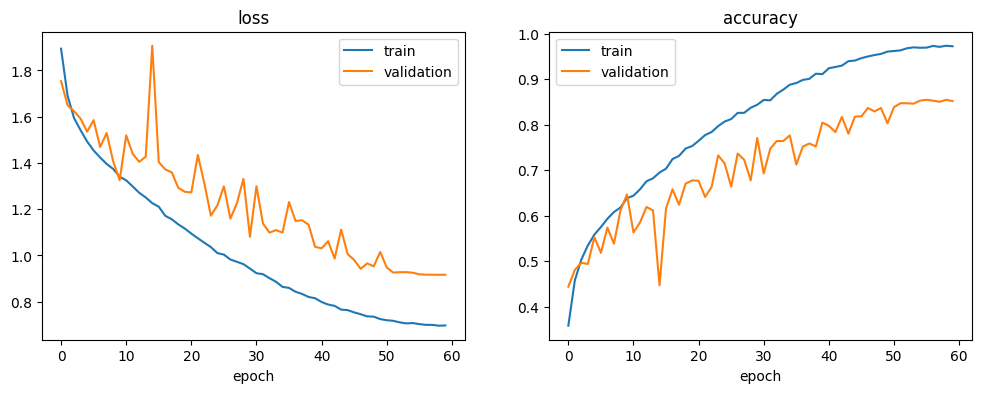

In [15]:
# Train the final model and save the weights of its best validation epoch
os.makedirs("../outputs/weights", exist_ok=True)
best, hist = run(cfg, 0, save="../outputs/weights/cnn.pth")

# Learning curves: if validation gets worse while training keeps improving, the model is overfitting
h = np.array(hist)   # columns: train loss, train acc, val loss, val acc
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (i, j, t) in zip(ax, [(0, 2, "loss"), (1, 3, "accuracy")]):
    a.plot(h[:, i], label="train"); a.plot(h[:, j], label="validation"); a.set_title(t); a.set_xlabel("epoch"); a.legend()
plt.show()

## 7. Results on train / validation / our test split

373834 parameters
train acc 0.9632
val   acc 0.8550
test  acc 0.8417
truck     0.808
frog      0.831
cat       0.812
plane     0.883
bird      0.859
car       0.878
equine    0.840
ship      0.884
deer      0.842
dog       0.780
Name: per-class test acc, dtype: float64


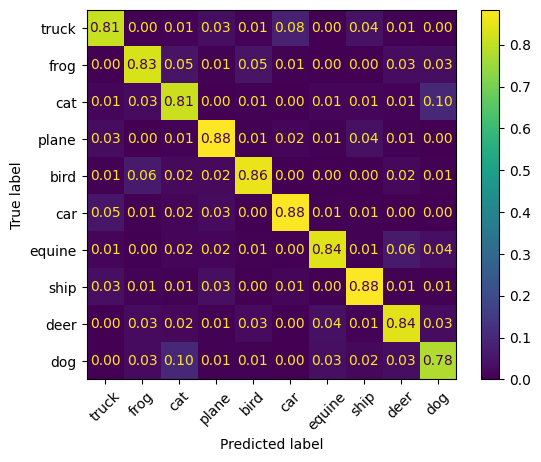

In [16]:
# Reload the saved weights (the same file we submit) and evaluate them
X, res = data(cfg["res"])[0], cfg["res"]
model = make(cfg)
model.load_state_dict(torch.load("../outputs/weights/cnn.pth"))
print(sum(p.numel() for p in model.parameters()), "parameters")
for name, s in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5s} acc {(predict(model, X[s], res, cfg['tta']).argmax(1) == y[s]).float().mean():.4f}")

# Predictions on our test split, saved for the comparison with the ViT (part f)
pred_te = predict(model, X[te], res, cfg["tta"]).argmax(1)
os.makedirs("../outputs/preds", exist_ok=True)
pd.DataFrame({"index": te, "true": y[te].numpy(), "cnn": pred_te.numpy()}).to_csv("../outputs/preds/cnn_test.csv", index=False)
print(pd.Series({c: (pred_te[y[te] == i] == i).float().mean().item() for c, i in encodings.items()}, name="per-class test acc").round(3))
# Confusion matrix: row = true class, column = predicted class, each row sums to 1
ConfusionMatrixDisplay.from_predictions(y[te], pred_te, display_labels=classes, xticks_rotation=45, normalize="true", values_format=".2f"); plt.show()

## 8. What does the CNN look at? (part g)

Each image comes with an object mask (white = object, black = background). On our test split we change only the object or only the background, and measure how much the accuracy drops:
- **Random noise** (Gaussian, σ = 0.3 on the 0–1 pixel scale) on the object only, then on the background only. If noise on the background hurts more, the model relies on the background more than on the object.
- **Background blanked:** the background is replaced by the average colour, so only the object is left.
- **Object blanked:** only the background is left. If accuracy stays well above 10 % (random guessing), the background alone gives away the class.
- **Background swapped:** the object is pasted onto the background of another random test image (whose own object is blanked).

The table gives the accuracy per class, to see which classes depend most on their background.

In [17]:
# Object masks of our test-split images (white = object), resized like the images
mask_paths = (PATH + "/archive/RIVAL10_Kaggle" + train["image_path"].str[7:].str.replace(".JPEG", "_merged_mask.JPEG")).iloc[te]
M = torch.from_numpy(np.stack([np.array(Image.open(p).convert("L").resize((224, 224))) for p in mask_paths]))[:, None]
m = (resize(M, res).float() / 255 > 0.5).float()   # 1 = object pixel
x0, fill = X[te].float() / 255, data(res)[1].cpu()   # images in 0-1; fill = mean colour of the training images
g = torch.Generator().manual_seed(0)                 # fixed seed: same noise every time
noise, other = torch.randn(x0.shape, generator=g), torch.randperm(len(te), generator=g)   # other = random partner image for the swap
print(f"object covers {m.mean():.0%} of the pixels on average")

# Each test builds a modified copy of the images (m keeps the object, 1 - m keeps the background)
tests = {
    "clean": lambda: x0,
    "noise on object": lambda: x0 + 0.3 * noise * m,
    "noise on background": lambda: x0 + 0.3 * noise * (1 - m),
    "background blanked": lambda: x0 * m + fill * (1 - m),
    "object blanked": lambda: x0 * (1 - m) + fill * m,
    # our object + the background of another image (whose own object is blanked)
    "background swapped": lambda: x0 * m + (x0[other] * (1 - m[other]) + fill * m[other]) * (1 - m),
}
rows = {}
for name, make_x in tests.items():
    p = predict(model, (make_x().clamp(0, 1) * 255).round().byte(), res, cfg["tta"]).argmax(1)   # back to 0-255, then predict
    rows[name] = {"all": (p == y[te]).float().mean().item(), **{c: (p[y[te] == i] == i).float().mean().item() for c, i in encodings.items()}}
pd.DataFrame(rows).T.round(3)   # accuracy: overall and per class

object covers 37% of the pixels on average


,all,truck,frog,cat,plane,bird,car,equine,ship,deer,dog
clean,0.842,0.808,0.831,0.812,0.883,0.859,0.878,0.840,0.884,0.842,0.780
noise on object,0.269,0.238,0.160,0.683,0.886,0.455,0.000,0.025,0.066,0.076,0.104
noise on background,0.276,0.417,0.047,0.906,0.117,0.100,0.094,0.242,0.270,0.028,0.538
background blanked,0.429,0.361,0.232,0.204,0.943,0.859,0.558,0.412,0.242,0.170,0.311
object blanked,0.311,0.142,0.241,0.034,0.829,0.790,0.016,0.088,0.465,0.461,0.035
background swapped,0.446,0.414,0.210,0.251,0.775,0.668,0.683,0.585,0.236,0.274,0.362


## 9. Kaggle file (Task 1 competition, not submitted yet)

In [18]:
# Kaggle images: same resizing, same model, same test-time flip
X_kaggle = resize(torch.from_numpy(np.stack(X_test)).permute(0, 3, 1, 2), res)
os.makedirs("../outputs/submissions", exist_ok=True)
# Kaggle format: id = image number ("00042.png" -> 42), label_name = predicted class name
pd.DataFrame({"id": test["id"].str[:5].astype(int), "label_name": [classes[i] for i in predict(model, X_kaggle, res, cfg["tta"]).argmax(1)]}).to_csv("../outputs/submissions/cnn.csv", index=False)
pd.read_csv("../outputs/submissions/cnn.csv").head()

,id,label_name
0,0,dog
1,1,bird
2,2,equine
3,3,plane
4,4,car
